# CUB-style bird bounding boxes for iNaturalist

This notebook fine-tunes a pretrained torchvision bird detector on the official
CUB-200-2011 bounding boxes, validates localization on held-out CUB images, and
uses the resulting detector to create one CUB-style bird box per iNaturalist
image.

Results are written to: Notebooks/Outputs/iNaturalist Outputs/Bounding Box Outputs/
## Output convention

The generated manifest uses CUB's zero-based pixel x, y, width, height fields:

* `bbox_x`, `bbox_y` — top-left corner
* `bbox_width`, `bbox_height` — box dimensions
* `bbox_right`, `bbox_bottom` — clipped bottom-right corner
* `bbox_area_fraction` — box area divided by image area

The highest-confidence bird detection is retained. Images without a detection at
the selected validation threshold keep empty box fields and receive a
`bbox_detection_status` explaining why. These boxes are **model-generated pseudo
labels**, not human annotations; inspect the QA samples before using them for
training.

## Execution notes

1. Run sections 1–5 to train and validate the detector.
2. Review CUB metrics and overlays before accepting the threshold.
3. Run sections 6–8 to annotate iNaturalist and export the manifest.
4. The inference progress file is append-only and keyed by the model checkpoint,
   threshold, and source manifest, so interrupted runs can safely resume.

The current project environment uses PyTorch/torchvision. TensorFlow and
Ultralytics are not required.


## 1. Configuration

All settings that normally need adjustment are in the next cell. Image roots may
be supplied explicitly when manifests were created on another machine. Leave an
override as `None` to translate the paths stored in the manifest (including
Windows `E:\...` paths when running under WSL).


In [1]:
from __future__ import annotations

import csv
import hashlib
import json
import math
import os
import random
import sys
import time
from collections import Counter
from datetime import datetime, timezone
from pathlib import Path, PurePosixPath, PureWindowsPath
from typing import Any, Iterable, Iterator, Sequence

import numpy as np
import pandas as pd
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
from IPython.display import display


def find_project_root(start: Path) -> Path:
    """Find the repository whether the kernel starts in its root or a subfolder."""
    start = start.resolve()
    candidates = [start, *start.parents]
    candidates += [candidate / "esp32_Classifier" for candidate in candidates]
    for candidate in candidates:
        if (candidate / "Notebooks" / "Outputs").is_dir():
            return candidate.resolve()
    raise FileNotFoundError(
        f"Could not find a project containing Notebooks/Outputs from {start}"
    )


PROJECT_ROOT = find_project_root(Path.cwd())
NOTEBOOK_DIR = PROJECT_ROOT / "Notebooks"
OUTPUTS_DIR = NOTEBOOK_DIR / "Outputs"

CUB_MANIFEST = OUTPUTS_DIR / "CUB Outputs" / "cub_200_2011_image_manifest.csv"
DIRECT_INAT_MANIFEST = OUTPUTS_DIR / "iNaturalist Outputs" / "bird_manifest.csv"
BRIDGE_MANIFEST = OUTPUTS_DIR / "Bridge Outputs" / "bird_bridge_manifest.csv"
TRAINING_MANIFEST = PROJECT_ROOT / "Models" / "Training Manifest" / "bird_training_manifest.csv"

# "auto" prefers the standalone 74,300-row bird manifest, then the bridge manifest.
# Use "training" only when intentionally annotating the smaller classifier subset.
INAT_MANIFEST_SOURCE = "auto"  # "auto" | "direct" | "bridge" | "training"

# Set these when stored absolute paths do not point to the mounted datasets.
# Each override must be the directory that directly contains the class folders.
CUB_IMAGE_ROOT_OVERRIDE: str | Path | None = None
INAT_IMAGE_ROOT_OVERRIDE: str | Path | None = None

BBOX_OUTPUT_DIR = OUTPUTS_DIR / "iNaturalist Outputs" / "Bounding Box Outputs"
CHECKPOINT_DIR = BBOX_OUTPUT_DIR / "checkpoints"
PREVIEW_DIR = BBOX_OUTPUT_DIR / "previews"

# Reproducibility and CUB split.
SEED = 1234
VALIDATION_FRACTION = 0.15  # stratified from the official CUB training split

# Detector training. A batch of 2 is suitable for a 6 GB GPU in most environments.
BATCH_SIZE = 2
INFERENCE_BATCH_SIZE = 4
NUM_WORKERS = 0  # safest in Windows/Jupyter; increase after the first successful run
EPOCHS = 8
LEARNING_RATE = 0.0025
MOMENTUM = 0.9
WEIGHT_DECAY = 0.0005
STEP_SIZE = 4
LR_GAMMA = 0.1
GRADIENT_CLIP_NORM = 10.0
FREEZE_BACKBONE = False

# COCO class 16 is bird. Keeping the pretrained COCO head preserves its bird prior.
BIRD_CLASS_ID = 16
MODEL_NAME = "fasterrcnn_mobilenet_v3_large_320_fpn"
MIN_EVALUATION_SCORE = 0.01
THRESHOLD_GRID = np.round(np.arange(0.05, 0.951, 0.025), 3)

# Workflow controls. Set a limit for a quick end-to-end test; None uses all rows.
RUN_TRAINING = True
RESUME_TRAINING = True
RUN_INATURALIST_INFERENCE = True
RESUME_INFERENCE = True
CUB_TRAIN_LIMIT: int | None = None
CUB_EVAL_LIMIT: int | None = None
INATURALIST_LIMIT: int | None = None
SAVE_QA_PREVIEWS = True
QA_PREVIEW_COUNT = 24

# A manual threshold overrides validation selection when not None.
MANUAL_CONFIDENCE_THRESHOLD: float | None = None

for directory in (BBOX_OUTPUT_DIR, CHECKPOINT_DIR, PREVIEW_DIR):
    directory.mkdir(parents=True, exist_ok=True)

print(f"Project root:       {PROJECT_ROOT}")
print(f"CUB manifest:       {CUB_MANIFEST}")
print(f"Direct iNat input:  {DIRECT_INAT_MANIFEST} (exists={DIRECT_INAT_MANIFEST.exists()})")
print(f"Bridge fallback:    {BRIDGE_MANIFEST} (exists={BRIDGE_MANIFEST.exists()})")
print(f"Output directory:   {BBOX_OUTPUT_DIR}")


Project root:       /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier
CUB manifest:       /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Notebooks/Outputs/CUB Outputs/cub_200_2011_image_manifest.csv
Direct iNat input:  /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Notebooks/Outputs/iNaturalist Outputs/bird_manifest.csv (exists=False)
Bridge fallback:    /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Notebooks/Outputs/Bridge Outputs/bird_bridge_manifest.csv (exists=True)
Output directory:   /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Notebooks/Outputs/iNaturalist Outputs/Bounding Box Outputs


## 2. Dependencies, reproducibility, and shared helpers

The torchvision model will download its official COCO weights on first use if
they are not already cached. This one-time step requires internet access.


In [2]:
try:
    import torch
    import torchvision
    from torch.utils.data import DataLoader, Dataset
    from torchvision.models.detection import (
        FasterRCNN_MobileNet_V3_Large_320_FPN_Weights,
        fasterrcnn_mobilenet_v3_large_320_fpn,
    )
    from torchvision.transforms.functional import pil_to_tensor
except ImportError as exc:
    raise ImportError(
        "This notebook requires torch and torchvision. Install compatible builds "
        "for your CUDA or CPU environment before continuing."
    ) from exc

if tuple(int(part) for part in torch.__version__.split("+")[0].split(".")[:2]) < (2, 0):
    raise RuntimeError(f"PyTorch 2.x or newer is required; found {torch.__version__}")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cuda":
    torch.backends.cudnn.benchmark = True

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print(f"Python:      {sys.version.split()[0]}")
print(f"PyTorch:     {torch.__version__}")
print(f"torchvision: {torchvision.__version__}")
print(f"Device:      {DEVICE}")
if DEVICE.type == "cuda":
    print(f"GPU:         {torch.cuda.get_device_name(0)}")


def utc_now() -> str:
    return datetime.now(timezone.utc).isoformat()


def sha256_file(path: Path, block_size: int = 1 << 20) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for block in iter(lambda: handle.read(block_size), b""):
            digest.update(block)
    return digest.hexdigest()


def translate_stored_path(value: Any) -> Path | None:
    """Translate native Windows paths to WSL and /mnt paths back to Windows."""
    if value is None or pd.isna(value) or not str(value).strip():
        return None
    text = str(value).strip()
    windows = PureWindowsPath(text)
    if os.name != "nt" and windows.drive:
        drive = windows.drive.rstrip(":").lower()
        return Path("/mnt") / drive / Path(*windows.parts[1:])
    posix = PurePosixPath(text.replace("\\", "/"))
    if os.name == "nt" and len(posix.parts) >= 4 and posix.parts[:2] == ("/", "mnt"):
        drive = posix.parts[2].upper() + ":\\"
        return Path(drive, *posix.parts[3:])
    return Path(text)


def clean_relative_path(value: Any) -> Path | None:
    if value is None or pd.isna(value) or not str(value).strip():
        return None
    parts = PurePosixPath(str(value).replace("\\", "/")).parts
    return Path(*[part for part in parts if part not in ("", "/", ".")])


def resolve_image_path(
    row: pd.Series,
    dataset: str,
    root_override: str | Path | None,
) -> Path:
    """Resolve a row from the CUB, direct iNat, bridge, or training manifest."""
    override_candidates: list[Path] = []
    stored_candidates: list[Path] = []
    root = translate_stored_path(root_override) if root_override is not None else None
    relative_fields = (
        ("photo_relative_path", "image_relative_path", "relative_path")
        if dataset == "inaturalist"
        else ("photo_relative_path", "image_relative_path", "relative_path")
    )

    if root is not None:
        for field in relative_fields:
            relative = clean_relative_path(row.get(field))
            if relative is None:
                continue
            variants = [relative]
            parts = relative.parts
            # Direct iNaturalist manifests store train_mini/train_mini/<class>/<file>.
            if dataset == "inaturalist" and len(parts) > 2 and parts[:2] == ("train_mini", "train_mini"):
                variants.insert(0, Path(*parts[2:]))
            # Bridge CUB paths can begin with images/ while the override is already images/.
            if dataset == "cub_200_2011" and parts and parts[0].lower() == "images":
                variants.insert(0, Path(*parts[1:]))
            override_candidates.extend(root / variant for variant in variants)

    for field in ("absolute_path", "image_path", "path"):
        translated = translate_stored_path(row.get(field))
        if translated is not None:
            stored_candidates.append(translated)

    # An explicit override takes precedence when it resolves. Stored paths do not
    # need an existence probe here; the dedicated validation cell checks them in bulk.
    for candidate in override_candidates:
        if candidate.is_file():
            return candidate.resolve()
    if override_candidates:
        return override_candidates[0]
    if stored_candidates:
        return stored_candidates[0]
    raise ValueError(f"No usable image path columns for {dataset} row {row.name}")


def safe_float(value: Any) -> float | None:
    try:
        number = float(value)
    except (TypeError, ValueError):
        return None
    return number if math.isfinite(number) else None


def collate_detection_batch(batch: Sequence[Any]) -> tuple:
    return tuple(zip(*batch))


def box_iou_one(box_a: Sequence[float] | None, box_b: Sequence[float] | None) -> float:
    if box_a is None or box_b is None:
        return 0.0
    ax1, ay1, ax2, ay2 = map(float, box_a)
    bx1, by1, bx2, by2 = map(float, box_b)
    ix1, iy1 = max(ax1, bx1), max(ay1, by1)
    ix2, iy2 = min(ax2, bx2), min(ay2, by2)
    intersection = max(0.0, ix2 - ix1) * max(0.0, iy2 - iy1)
    union = max(0.0, ax2 - ax1) * max(0.0, ay2 - ay1)
    union += max(0.0, bx2 - bx1) * max(0.0, by2 - by1) - intersection
    return intersection / union if union > 0 else 0.0


def json_safe(value: Any) -> Any:
    if isinstance(value, Path):
        return str(value)
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating,)):
        return None if not np.isfinite(value) else float(value)
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, dict):
        return {str(key): json_safe(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_safe(item) for item in value]
    if pd.isna(value) if not isinstance(value, (list, tuple, dict)) else False:
        return None
    return value


Python:      3.12.15
PyTorch:     2.14.1+cu130
torchvision: 0.29.1+cu130
Device:      cuda
GPU:         NVIDIA GeForce RTX 3060 Laptop GPU


## 3. Load and normalize manifests

The CUB manifest supplies supervised boxes. For iNaturalist, `auto` uses the
standalone `bird_manifest.csv` if present and otherwise selects the 74,300
iNaturalist rows from the bridge manifest. Internal helper columns start with `_`
and are not copied to the exported manifest.


In [3]:
if not CUB_MANIFEST.is_file():
    raise FileNotFoundError(f"CUB manifest not found: {CUB_MANIFEST}")


def select_inaturalist_manifest() -> tuple[Path, str]:
    requested = INAT_MANIFEST_SOURCE.lower()
    if requested == "auto":
        if DIRECT_INAT_MANIFEST.is_file():
            return DIRECT_INAT_MANIFEST, "direct"
        if BRIDGE_MANIFEST.is_file():
            return BRIDGE_MANIFEST, "bridge"
        raise FileNotFoundError(
            f"Neither {DIRECT_INAT_MANIFEST} nor {BRIDGE_MANIFEST} exists"
        )
    choices = {
        "direct": DIRECT_INAT_MANIFEST,
        "bridge": BRIDGE_MANIFEST,
        "training": TRAINING_MANIFEST,
    }
    if requested not in choices:
        raise ValueError(f"Unknown INAT_MANIFEST_SOURCE={INAT_MANIFEST_SOURCE!r}")
    path = choices[requested]
    if not path.is_file():
        raise FileNotFoundError(path)
    return path, requested


INAT_MANIFEST, INAT_MANIFEST_KIND = select_inaturalist_manifest()
cub_raw = pd.read_csv(CUB_MANIFEST, encoding="utf-8-sig", low_memory=False)
inat_raw_all = pd.read_csv(INAT_MANIFEST, encoding="utf-8-sig", low_memory=False)

if INAT_MANIFEST_KIND == "bridge":
    if "source_dataset" not in inat_raw_all:
        raise ValueError("Bridge manifest is missing source_dataset")
    inat_raw = inat_raw_all.loc[
        inat_raw_all["source_dataset"].eq("inaturalist")
    ].copy().reset_index(drop=True)
elif INAT_MANIFEST_KIND == "training":
    inat_raw = inat_raw_all.loc[
        inat_raw_all["source_dataset"].eq("inaturalist")
    ].copy().reset_index(drop=True)
else:
    inat_raw = inat_raw_all.copy().reset_index(drop=True)

required_cub = {
    "image_id", "class_id", "split", "bbox_x", "bbox_y", "bbox_width",
    "bbox_height", "width_px", "height_px",
}
missing_cub = sorted(required_cub - set(cub_raw.columns))
if missing_cub:
    raise ValueError(f"CUB manifest is missing columns: {missing_cub}")

cub = cub_raw.copy()
for column in ("bbox_x", "bbox_y", "bbox_width", "bbox_height", "width_px", "height_px"):
    cub[column] = pd.to_numeric(cub[column], errors="coerce")

if cub[list(required_cub - {"image_id", "class_id", "split"})].isna().any().any():
    raise ValueError("CUB contains missing or non-numeric dimensions/bounding boxes")
if not cub["split"].isin(["train", "test"]).all():
    raise ValueError(f"Unexpected CUB split values: {sorted(cub['split'].unique())}")

# Convert xywh to clipped xyxy while preserving an audit flag for source anomalies.
cub["_source_x2"] = cub["bbox_x"] + cub["bbox_width"]
cub["_source_y2"] = cub["bbox_y"] + cub["bbox_height"]
cub["_bbox_was_clipped"] = (
    cub["bbox_x"].lt(0) | cub["bbox_y"].lt(0)
    | cub["_source_x2"].gt(cub["width_px"])
    | cub["_source_y2"].gt(cub["height_px"])
)
cub["_x1"] = cub["bbox_x"].clip(lower=0).clip(upper=cub["width_px"])
cub["_y1"] = cub["bbox_y"].clip(lower=0).clip(upper=cub["height_px"])
cub["_x2"] = cub["_source_x2"].clip(lower=0).clip(upper=cub["width_px"])
cub["_y2"] = cub["_source_y2"].clip(lower=0).clip(upper=cub["height_px"])
if (cub["_x2"] <= cub["_x1"]).any() or (cub["_y2"] <= cub["_y1"]).any():
    raise ValueError("CUB contains an empty box after clipping")

cub["_path"] = cub.apply(
    lambda row: str(resolve_image_path(row, "cub_200_2011", CUB_IMAGE_ROOT_OVERRIDE)),
    axis=1,
)

# Normalize direct-manifest width/height and identifiers without replacing originals.
inat = inat_raw.copy()
if "width_px" not in inat:
    inat["width_px"] = inat.get("width")
if "height_px" not in inat:
    inat["height_px"] = inat.get("height")
inat["width_px"] = pd.to_numeric(inat["width_px"], errors="coerce")
inat["height_px"] = pd.to_numeric(inat["height_px"], errors="coerce")

if "source_image_id" in inat:
    source_ids = inat["source_image_id"]
elif "image_id" in inat:
    source_ids = inat["image_id"]
else:
    raise ValueError("iNaturalist manifest has neither source_image_id nor image_id")
inat["_source_image_id"] = source_ids.astype(str)
if inat["_source_image_id"].duplicated().any():
    duplicates = inat.loc[inat["_source_image_id"].duplicated(), "_source_image_id"].head().tolist()
    raise ValueError(f"Duplicate iNaturalist image IDs, examples: {duplicates}")

inat["_row_index"] = np.arange(len(inat), dtype=np.int64)
inat["_path"] = inat.apply(
    lambda row: str(resolve_image_path(row, "inaturalist", INAT_IMAGE_ROOT_OVERRIDE)),
    axis=1,
)

print(f"CUB rows:                 {len(cub):,}")
print(f"CUB boxes clipped:        {int(cub['_bbox_was_clipped'].sum()):,}")
print(f"iNaturalist input:        {INAT_MANIFEST}")
print(f"iNaturalist input kind:   {INAT_MANIFEST_KIND}")
print(f"iNaturalist rows:         {len(inat):,}")

display(cub[["image_id", "split", "_path", "_x1", "_y1", "_x2", "_y2"]].head())
display(inat[["_source_image_id", "_path", "width_px", "height_px"]].head())


CUB rows:                 11,788
CUB boxes clipped:        30
iNaturalist input:        /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Notebooks/Outputs/Bridge Outputs/bird_bridge_manifest.csv
iNaturalist input kind:   bridge
iNaturalist rows:         74,300


,image_id,split,_path,_x1,_y1,_x2,_y2
0,1,test,/mnt/e/Datasets/CUB_200/CUB_200_2011/images/00...,60.0,27.0,385.0,331.0
1,2,train,/mnt/e/Datasets/CUB_200/CUB_200_2011/images/00...,139.0,30.0,292.0,294.0
2,3,test,/mnt/e/Datasets/CUB_200/CUB_200_2011/images/00...,14.0,112.0,402.0,298.0
3,4,train,/mnt/e/Datasets/CUB_200/CUB_200_2011/images/00...,112.0,90.0,367.0,332.0
4,5,train,/mnt/e/Datasets/CUB_200/CUB_200_2011/images/00...,70.0,50.0,204.0,353.0


,_source_image_id,_path,width_px,height_px
0,53,/mnt/e/Datasets/iNaturalist/train_mini/train_m...,429,417
1,73,/mnt/e/Datasets/iNaturalist/train_mini/train_m...,500,401
2,82,/mnt/e/Datasets/iNaturalist/train_mini/train_m...,500,372
3,90,/mnt/e/Datasets/iNaturalist/train_mini/train_m...,500,350
4,99,/mnt/e/Datasets/iNaturalist/train_mini/train_m...,500,480


### Path validation

The manifests may remain usable even after the datasets move, provided the two
root overrides point directly at their class-folder directories. Training or
inference stops early if any selected image is unavailable.


In [4]:
def validate_paths(frame: pd.DataFrame, label: str, limit: int | None = None) -> None:
    selected = frame if limit is None else frame.head(limit)
    missing = [path for path in selected["_path"] if not Path(path).is_file()]
    if missing:
        examples = "\n".join(f"  - {path}" for path in missing[:10])
        raise FileNotFoundError(
            f"{len(missing):,} of {len(selected):,} selected {label} files are missing. "
            f"Set the corresponding image-root override. Examples:\n{examples}"
        )
    print(f"Validated {len(selected):,} {label} image paths")


# These checks intentionally occur before model construction or a weight download.
validate_paths(cub, "CUB")
if RUN_INATURALIST_INFERENCE:
    validate_paths(inat, "iNaturalist", INATURALIST_LIMIT)


Validated 11,788 CUB image paths
Validated 74,300 iNaturalist image paths


## 4. CUB dataset and deterministic splits

The official CUB test set remains untouched. Validation is selected from the
official training set with a deterministic per-class shuffle, ensuring every CUB
class remains represented in training.


In [5]:
def assign_cub_model_splits(frame: pd.DataFrame) -> pd.DataFrame:
    result = frame.copy()
    result["_model_split"] = result["split"].map({"train": "train", "test": "test"})
    rng = np.random.default_rng(SEED)
    for _, group in result.loc[result["split"].eq("train")].groupby("class_id", sort=True):
        indices = group.index.to_numpy().copy()
        rng.shuffle(indices)
        validation_count = max(1, int(round(len(indices) * VALIDATION_FRACTION)))
        validation_count = min(validation_count, len(indices) - 1)
        result.loc[indices[:validation_count], "_model_split"] = "validation"
    return result


cub = assign_cub_model_splits(cub)
cub_splits = {
    name: cub.loc[cub["_model_split"].eq(name)].reset_index(drop=True)
    for name in ("train", "validation", "test")
}

if CUB_TRAIN_LIMIT is not None:
    cub_splits["train"] = cub_splits["train"].head(CUB_TRAIN_LIMIT).copy()
if CUB_EVAL_LIMIT is not None:
    cub_splits["validation"] = cub_splits["validation"].head(CUB_EVAL_LIMIT).copy()
    cub_splits["test"] = cub_splits["test"].head(CUB_EVAL_LIMIT).copy()

split_table = pd.DataFrame(
    {
        "images": {name: len(frame) for name, frame in cub_splits.items()},
        "classes": {name: frame["class_id"].nunique() for name, frame in cub_splits.items()},
        "clipped_source_boxes": {
            name: int(frame["_bbox_was_clipped"].sum()) for name, frame in cub_splits.items()
        },
    }
)
display(split_table)

assert set(cub_splits["train"]["image_id"]).isdisjoint(cub_splits["validation"]["image_id"])
assert set(cub_splits["train"]["image_id"]).isdisjoint(cub_splits["test"]["image_id"])
assert set(cub_splits["validation"]["image_id"]).isdisjoint(cub_splits["test"]["image_id"])


,images,classes,clipped_source_boxes
train,5194,200,14
validation,800,200,0
test,5794,200,16


In [6]:
class CUBDetectionDataset(Dataset):
    def __init__(self, frame: pd.DataFrame, training: bool = False):
        self.frame = frame.reset_index(drop=True)
        self.training = training

    def __len__(self) -> int:
        return len(self.frame)

    def __getitem__(self, index: int) -> tuple[torch.Tensor, dict[str, torch.Tensor]]:
        row = self.frame.iloc[index]
        with Image.open(row["_path"]) as opened:
            # Official CUB boxes use the JPEG's stored pixel coordinate system.
            image = opened.convert("RGB")

        actual_width, actual_height = image.size
        manifest_width, manifest_height = float(row["width_px"]), float(row["height_px"])
        scale_x = actual_width / manifest_width
        scale_y = actual_height / manifest_height
        box = torch.tensor(
            [[row["_x1"] * scale_x, row["_y1"] * scale_y,
              row["_x2"] * scale_x, row["_y2"] * scale_y]],
            dtype=torch.float32,
        )
        image_tensor = pil_to_tensor(image).float() / 255.0

        if self.training and torch.rand(()) < 0.5:
            image_tensor = torch.flip(image_tensor, dims=[2])
            old_x1, old_x2 = box[:, 0].clone(), box[:, 2].clone()
            box[:, 0] = actual_width - old_x2
            box[:, 2] = actual_width - old_x1

        target = {
            "boxes": box,
            "labels": torch.tensor([BIRD_CLASS_ID], dtype=torch.int64),
            "image_id": torch.tensor([int(row["image_id"])], dtype=torch.int64),
            "area": (box[:, 2] - box[:, 0]) * (box[:, 3] - box[:, 1]),
            "iscrowd": torch.zeros((1,), dtype=torch.int64),
        }
        return image_tensor, target


class ImageInferenceDataset(Dataset):
    def __init__(self, frame: pd.DataFrame):
        self.frame = frame.reset_index(drop=True)

    def __len__(self) -> int:
        return len(self.frame)

    def __getitem__(self, index: int) -> tuple[torch.Tensor, dict[str, Any]]:
        row = self.frame.iloc[index]
        with Image.open(row["_path"]) as opened:
            image = opened.convert("RGB")
        width, height = image.size
        metadata = {
            "row_index": int(row["_row_index"]),
            "source_image_id": str(row["_source_image_id"]),
            "path": str(row["_path"]),
            "bbox_image_width_px": width,
            "bbox_image_height_px": height,
        }
        return pil_to_tensor(image).float() / 255.0, metadata


train_loader = DataLoader(
    CUBDetectionDataset(cub_splits["train"], training=True),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    collate_fn=collate_detection_batch,
    pin_memory=DEVICE.type == "cuda",
)
validation_loader = DataLoader(
    CUBDetectionDataset(cub_splits["validation"]),
    batch_size=INFERENCE_BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    collate_fn=collate_detection_batch,
    pin_memory=DEVICE.type == "cuda",
)
test_loader = DataLoader(
    CUBDetectionDataset(cub_splits["test"]),
    batch_size=INFERENCE_BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    collate_fn=collate_detection_batch,
    pin_memory=DEVICE.type == "cuda",
)

images, targets = next(iter(train_loader))
assert images[0].shape[0] == 3 and images[0].dtype == torch.float32
assert targets[0]["boxes"].shape == (1, 4)
assert int(targets[0]["labels"][0]) == BIRD_CLASS_ID
print("Dataset smoke test passed:", images[0].shape, targets[0]["boxes"].tolist())


Dataset smoke test passed: torch.Size([3, 346, 500]) [[91.0, 45.0, 318.0, 321.0]]


## 5. Detector construction, training, and checkpoints

The COCO prediction head is retained so class 16 remains `bird`. Fine-tuning on
CUB adapts localization to fine-grained bird photography while preserving the
pretrained bird prior. Each epoch writes an atomic checkpoint; rerunning the cell
resumes from the latest checkpoint when enabled.


In [7]:
def build_detector(pretrained: bool = True) -> torch.nn.Module:
    weights = (
        FasterRCNN_MobileNet_V3_Large_320_FPN_Weights.DEFAULT if pretrained else None
    )
    model = fasterrcnn_mobilenet_v3_large_320_fpn(
        weights=weights,
        weights_backbone=None if pretrained else None,
        trainable_backbone_layers=6,
        min_size=320,
        max_size=1024,
    )
    if FREEZE_BACKBONE:
        for parameter in model.backbone.parameters():
            parameter.requires_grad = False
    model.roi_heads.score_thresh = MIN_EVALUATION_SCORE
    return model


LATEST_CHECKPOINT = CHECKPOINT_DIR / "cub_bird_detector_latest.pt"
BEST_CHECKPOINT = CHECKPOINT_DIR / "cub_bird_detector_best.pt"
will_resume_training = RESUME_TRAINING and LATEST_CHECKPOINT.is_file()
model = build_detector(pretrained=RUN_TRAINING and not will_resume_training).to(DEVICE)
trainable_parameters = [parameter for parameter in model.parameters() if parameter.requires_grad]
optimizer = torch.optim.SGD(
    trainable_parameters,
    lr=LEARNING_RATE,
    momentum=MOMENTUM,
    weight_decay=WEIGHT_DECAY,
)
scheduler = torch.optim.lr_scheduler.StepLR(
    optimizer, step_size=STEP_SIZE, gamma=LR_GAMMA
)

history: list[dict[str, Any]] = []
start_epoch = 0
best_validation_loss = math.inf

if RESUME_TRAINING and LATEST_CHECKPOINT.is_file():
    checkpoint = torch.load(LATEST_CHECKPOINT, map_location=DEVICE, weights_only=False)
    model.load_state_dict(checkpoint["model_state"])
    optimizer.load_state_dict(checkpoint["optimizer_state"])
    scheduler.load_state_dict(checkpoint["scheduler_state"])
    start_epoch = int(checkpoint["epoch"]) + 1
    history = list(checkpoint.get("history", []))
    best_validation_loss = float(checkpoint.get("best_validation_loss", math.inf))
    print(f"Resumed at epoch {start_epoch + 1} from {LATEST_CHECKPOINT}")


def atomic_torch_save(payload: dict[str, Any], destination: Path) -> None:
    temporary = destination.with_suffix(destination.suffix + ".tmp")
    torch.save(payload, temporary)
    temporary.replace(destination)


def move_targets(targets: Sequence[dict[str, torch.Tensor]]) -> list[dict[str, torch.Tensor]]:
    return [{key: value.to(DEVICE) for key, value in target.items()} for target in targets]


def loss_on_loader(loader: DataLoader) -> float:
    # torchvision detectors expose losses only in training mode. No gradients or
    # optimizer updates occur here; BatchNorm layers are frozen explicitly.
    model.train()
    batch_norm_states = []
    for module in model.modules():
        if isinstance(module, torch.nn.modules.batchnorm._BatchNorm):
            batch_norm_states.append((module, module.training))
            module.eval()
    losses = []
    with torch.no_grad():
        for images, targets in loader:
            images = [image.to(DEVICE, non_blocking=True) for image in images]
            targets = move_targets(targets)
            loss_dict = model(images, targets)
            losses.append(float(sum(loss_dict.values()).item()))
    for module, was_training in batch_norm_states:
        module.train(was_training)
    return float(np.mean(losses)) if losses else math.nan


def train_one_epoch(loader: DataLoader) -> dict[str, float]:
    model.train()
    totals: Counter[str] = Counter()
    batches = 0
    started = time.perf_counter()
    for batch_index, (images, targets) in enumerate(loader, start=1):
        images = [image.to(DEVICE, non_blocking=True) for image in images]
        targets = move_targets(targets)
        optimizer.zero_grad(set_to_none=True)
        loss_dict = model(images, targets)
        loss = sum(loss_dict.values())
        if not torch.isfinite(loss):
            raise FloatingPointError(f"Non-finite training loss: {loss_dict}")
        loss.backward()
        torch.nn.utils.clip_grad_norm_(trainable_parameters, GRADIENT_CLIP_NORM)
        optimizer.step()
        totals.update({name: float(value.detach().item()) for name, value in loss_dict.items()})
        totals["total_loss"] += float(loss.detach().item())
        batches += 1
        if batch_index % 100 == 0 or batch_index == len(loader):
            print(
                f"  batch {batch_index:>4}/{len(loader)} | "
                f"loss {totals['total_loss'] / batches:.4f}",
                flush=True,
            )
    metrics = {name: value / batches for name, value in totals.items()}
    metrics["minutes"] = (time.perf_counter() - started) / 60
    return metrics


Downloading: "https://download.pytorch.org/models/fasterrcnn_mobilenet_v3_large_320_fpn-907ea3f9.pth" to /home/joe/.cache/torch/hub/checkpoints/fasterrcnn_mobilenet_v3_large_320_fpn-907ea3f9.pth


100.0%


Epoch 1/8 | lr=0.0025
  batch  100/2597 | loss 1.0396
  batch  200/2597 | loss 1.0824
  batch  300/2597 | loss 1.0854
  batch  400/2597 | loss 1.0645
  batch  500/2597 | loss 1.0611
  batch  600/2597 | loss 1.0577
  batch  700/2597 | loss 1.0589
  batch  800/2597 | loss 1.0674
  batch  900/2597 | loss 1.0573
  batch 1000/2597 | loss 1.0592
  batch 1100/2597 | loss 1.0555
  batch 1200/2597 | loss 1.0493
  batch 1300/2597 | loss 1.0423
  batch 1400/2597 | loss 1.0360
  batch 1500/2597 | loss 1.0304
  batch 1600/2597 | loss 1.0308
  batch 1700/2597 | loss 1.0305
  batch 1800/2597 | loss 1.0300
  batch 1900/2597 | loss 1.0291
  batch 2000/2597 | loss 1.0307
  batch 2100/2597 | loss 1.0296
  batch 2200/2597 | loss 1.0311
  batch 2300/2597 | loss 1.0322
  batch 2400/2597 | loss 1.0309
  batch 2500/2597 | loss 1.0284
  batch 2597/2597 | loss 1.0249
  train=1.0249 | validation=1.0202 | best=True
Epoch 2/8 | lr=0.0025
  batch  100/2597 | loss 0.9490
  batch  200/2597 | loss 0.9394
  batch  300/

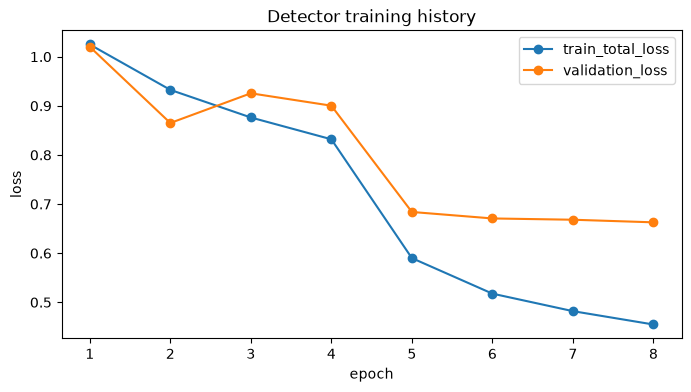

In [8]:
if RUN_TRAINING:
    for epoch in range(start_epoch, EPOCHS):
        print(f"Epoch {epoch + 1}/{EPOCHS} | lr={optimizer.param_groups[0]['lr']:.6g}")
        train_metrics = train_one_epoch(train_loader)
        validation_loss = loss_on_loader(validation_loader)
        scheduler.step()
        row = {
            "epoch": epoch + 1,
            **{f"train_{key}": value for key, value in train_metrics.items()},
            "validation_loss": validation_loss,
            "learning_rate": optimizer.param_groups[0]["lr"],
        }
        history.append(row)
        improved = validation_loss < best_validation_loss
        if improved:
            best_validation_loss = validation_loss
        payload = {
            "epoch": epoch,
            "model_name": MODEL_NAME,
            "bird_class_id": BIRD_CLASS_ID,
            "model_state": model.state_dict(),
            "optimizer_state": optimizer.state_dict(),
            "scheduler_state": scheduler.state_dict(),
            "history": history,
            "best_validation_loss": best_validation_loss,
            "cub_manifest_sha256": sha256_file(CUB_MANIFEST),
            "created_utc": utc_now(),
        }
        atomic_torch_save(payload, LATEST_CHECKPOINT)
        if improved:
            atomic_torch_save(payload, BEST_CHECKPOINT)
        pd.DataFrame(history).to_csv(
            BBOX_OUTPUT_DIR / "cub_bird_detector_training_history.csv", index=False
        )
        print(
            f"  train={train_metrics['total_loss']:.4f} | "
            f"validation={validation_loss:.4f} | best={improved}"
        )
else:
    print("RUN_TRAINING=False; using an existing checkpoint")

checkpoint_to_load = BEST_CHECKPOINT if BEST_CHECKPOINT.is_file() else LATEST_CHECKPOINT
if not checkpoint_to_load.is_file():
    raise FileNotFoundError(
        "No trained checkpoint exists. Set RUN_TRAINING=True and run this cell."
    )
checkpoint = torch.load(checkpoint_to_load, map_location=DEVICE, weights_only=False)
if checkpoint.get("cub_manifest_sha256") != sha256_file(CUB_MANIFEST):
    raise ValueError("Checkpoint was trained from a different CUB manifest")
model.load_state_dict(checkpoint["model_state"])
model.eval()
print(f"Loaded detector: {checkpoint_to_load}")

if history:
    pd.DataFrame(history).set_index("epoch")[["train_total_loss", "validation_loss"]].plot(
        figsize=(8, 4), marker="o", title="Detector training history"
    )
    plt.ylabel("loss")
    plt.show()


## 6. CUB localization evaluation and confidence threshold

For each image, evaluation retains the highest-scoring COCO `bird` prediction.
Threshold selection uses validation data only. Because every CUB image is a
positive bird example, validation cannot measure false positives on non-bird
images; the selected threshold is therefore the **highest threshold within one
percentage point of the best validation Recall@0.50**. This favors a conservative
point on the recall plateau. The official CUB test set is reported afterward and
does not influence selection.


,threshold,images,detections,detection_rate,mean_iou_all_images,median_iou_detected,recall_iou_50,recall_iou_75,multiple_bird_detection_rate,selected
0,0.050,800,800,1.00000,0.900877,0.922421,0.99375,0.96375,0.03625,False
1,0.075,800,800,1.00000,0.900877,0.922421,0.99375,0.96375,0.03625,False
2,0.100,800,800,1.00000,0.900877,0.922421,0.99375,0.96375,0.03625,False
3,0.125,800,800,1.00000,0.900877,0.922421,0.99375,0.96375,0.03625,False
4,0.150,800,800,1.00000,0.900877,0.922421,0.99375,0.96375,0.03625,False
5,0.175,800,800,1.00000,0.900877,0.922421,0.99375,0.96375,0.03625,False
6,0.200,800,800,1.00000,0.900877,0.922421,0.99375,0.96375,0.03625,False
7,0.225,800,800,1.00000,0.900877,0.922421,0.99375,0.96375,0.03625,False
8,0.250,800,800,1.00000,0.900877,0.922421,0.99375,0.96375,0.03625,False
9,0.275,800,800,1.00000,0.900877,0.922421,0.99375,0.96375,0.03625,False


Selected confidence threshold: 0.950


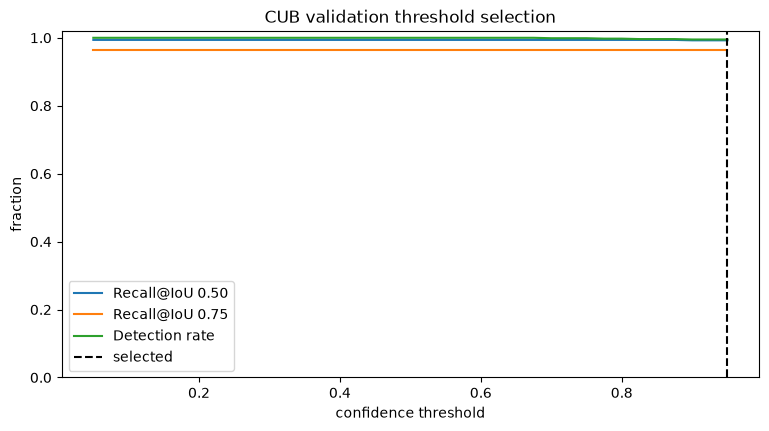

In [9]:
def highest_bird_prediction(output: dict[str, torch.Tensor]) -> dict[str, Any]:
    labels = output["labels"].detach().cpu()
    scores = output["scores"].detach().cpu()
    boxes = output["boxes"].detach().cpu()
    bird_indices = torch.nonzero(labels.eq(BIRD_CLASS_ID), as_tuple=False).flatten()
    if len(bird_indices) == 0:
        return {"score": None, "box": None, "bird_detection_count": 0}
    # torchvision predictions are normally score-sorted; argmax makes that explicit.
    local_index = int(torch.argmax(scores[bird_indices]).item())
    best_index = int(bird_indices[local_index].item())
    return {
        "score": float(scores[best_index].item()),
        "box": boxes[best_index].tolist(),
        "bird_detection_count": int(len(bird_indices)),
    }


def predict_cub_loader(loader: DataLoader, frame: pd.DataFrame) -> pd.DataFrame:
    model.eval()
    records: list[dict[str, Any]] = []
    position = 0
    with torch.inference_mode():
        for images, targets in loader:
            outputs = model([image.to(DEVICE, non_blocking=True) for image in images])
            for image, target, output in zip(images, targets, outputs):
                row = frame.iloc[position]
                prediction = highest_bird_prediction(output)
                ground_truth = target["boxes"][0].tolist()
                score = prediction["score"]
                records.append(
                    {
                        "image_id": int(row["image_id"]),
                        "class_id": int(row["class_id"]),
                        "path": row["_path"],
                        "score": np.nan if score is None else score,
                        "predicted_box": prediction["box"],
                        "ground_truth_box": ground_truth,
                        "iou_if_detected": box_iou_one(prediction["box"], ground_truth),
                        "bird_detection_count": prediction["bird_detection_count"],
                        "image_width": int(image.shape[2]),
                        "image_height": int(image.shape[1]),
                    }
                )
                position += 1
    if position != len(frame):
        raise AssertionError(f"Predicted {position} rows for a {len(frame)}-row frame")
    return pd.DataFrame(records)


validation_predictions = predict_cub_loader(
    validation_loader, cub_splits["validation"]
)


def metrics_at_threshold(predictions: pd.DataFrame, threshold: float) -> dict[str, Any]:
    accepted = predictions["score"].fillna(-1).ge(threshold)
    effective_iou = predictions["iou_if_detected"].where(accepted, 0.0)
    detected_iou = predictions.loc[accepted, "iou_if_detected"]
    return {
        "threshold": float(threshold),
        "images": int(len(predictions)),
        "detections": int(accepted.sum()),
        "detection_rate": float(accepted.mean()),
        "mean_iou_all_images": float(effective_iou.mean()),
        "median_iou_detected": float(detected_iou.median()) if len(detected_iou) else 0.0,
        "recall_iou_50": float(effective_iou.ge(0.50).mean()),
        "recall_iou_75": float(effective_iou.ge(0.75).mean()),
        "multiple_bird_detection_rate": float(
            predictions["bird_detection_count"].gt(1).mean()
        ),
    }


threshold_metrics = pd.DataFrame(
    [metrics_at_threshold(validation_predictions, threshold) for threshold in THRESHOLD_GRID]
)
maximum_recall = threshold_metrics["recall_iou_50"].max()
eligible = threshold_metrics.loc[
    threshold_metrics["recall_iou_50"].ge(maximum_recall - 0.01)
]
selected_threshold = (
    float(MANUAL_CONFIDENCE_THRESHOLD)
    if MANUAL_CONFIDENCE_THRESHOLD is not None
    else float(eligible["threshold"].max())
)
if not 0 <= selected_threshold <= 1:
    raise ValueError(f"Invalid confidence threshold: {selected_threshold}")

threshold_metrics.to_csv(
    BBOX_OUTPUT_DIR / "cub_validation_threshold_metrics.csv", index=False
)
display(
    threshold_metrics.assign(
        selected=threshold_metrics["threshold"].eq(selected_threshold)
    )
)
print(f"Selected confidence threshold: {selected_threshold:.3f}")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(threshold_metrics["threshold"], threshold_metrics["recall_iou_50"], label="Recall@IoU 0.50")
ax.plot(threshold_metrics["threshold"], threshold_metrics["recall_iou_75"], label="Recall@IoU 0.75")
ax.plot(threshold_metrics["threshold"], threshold_metrics["detection_rate"], label="Detection rate")
ax.axvline(selected_threshold, color="black", linestyle="--", label="selected")
ax.set(xlabel="confidence threshold", ylabel="fraction", ylim=(0, 1.02), title="CUB validation threshold selection")
ax.legend()
plt.show()


In [10]:
test_predictions = predict_cub_loader(test_loader, cub_splits["test"])
validation_result = metrics_at_threshold(validation_predictions, selected_threshold)
test_result = metrics_at_threshold(test_predictions, selected_threshold)
cub_metrics = pd.DataFrame(
    [
        {"split": "validation", **validation_result},
        {"split": "test", **test_result},
    ]
)
cub_metrics.to_csv(BBOX_OUTPUT_DIR / "cub_bird_detector_metrics.csv", index=False)
display(cub_metrics.set_index("split"))

if test_result["recall_iou_50"] < 0.50:
    print(
        "WARNING: CUB test Recall@IoU 0.50 is below 50%. Review training and QA "
        "before treating iNaturalist predictions as usable pseudo-labels."
    )


,threshold,images,detections,detection_rate,mean_iou_all_images,median_iou_detected,recall_iou_50,recall_iou_75,multiple_bird_detection_rate
split,,,,,,,,,
validation,0.95,800,796,0.99500,0.899000,0.922480,0.992500,0.963750,0.03625
test,0.95,5794,5740,0.99068,0.893583,0.923271,0.987401,0.941146,0.03262


Lowest-IoU accepted CUB test predictions (green=ground truth, red=prediction)


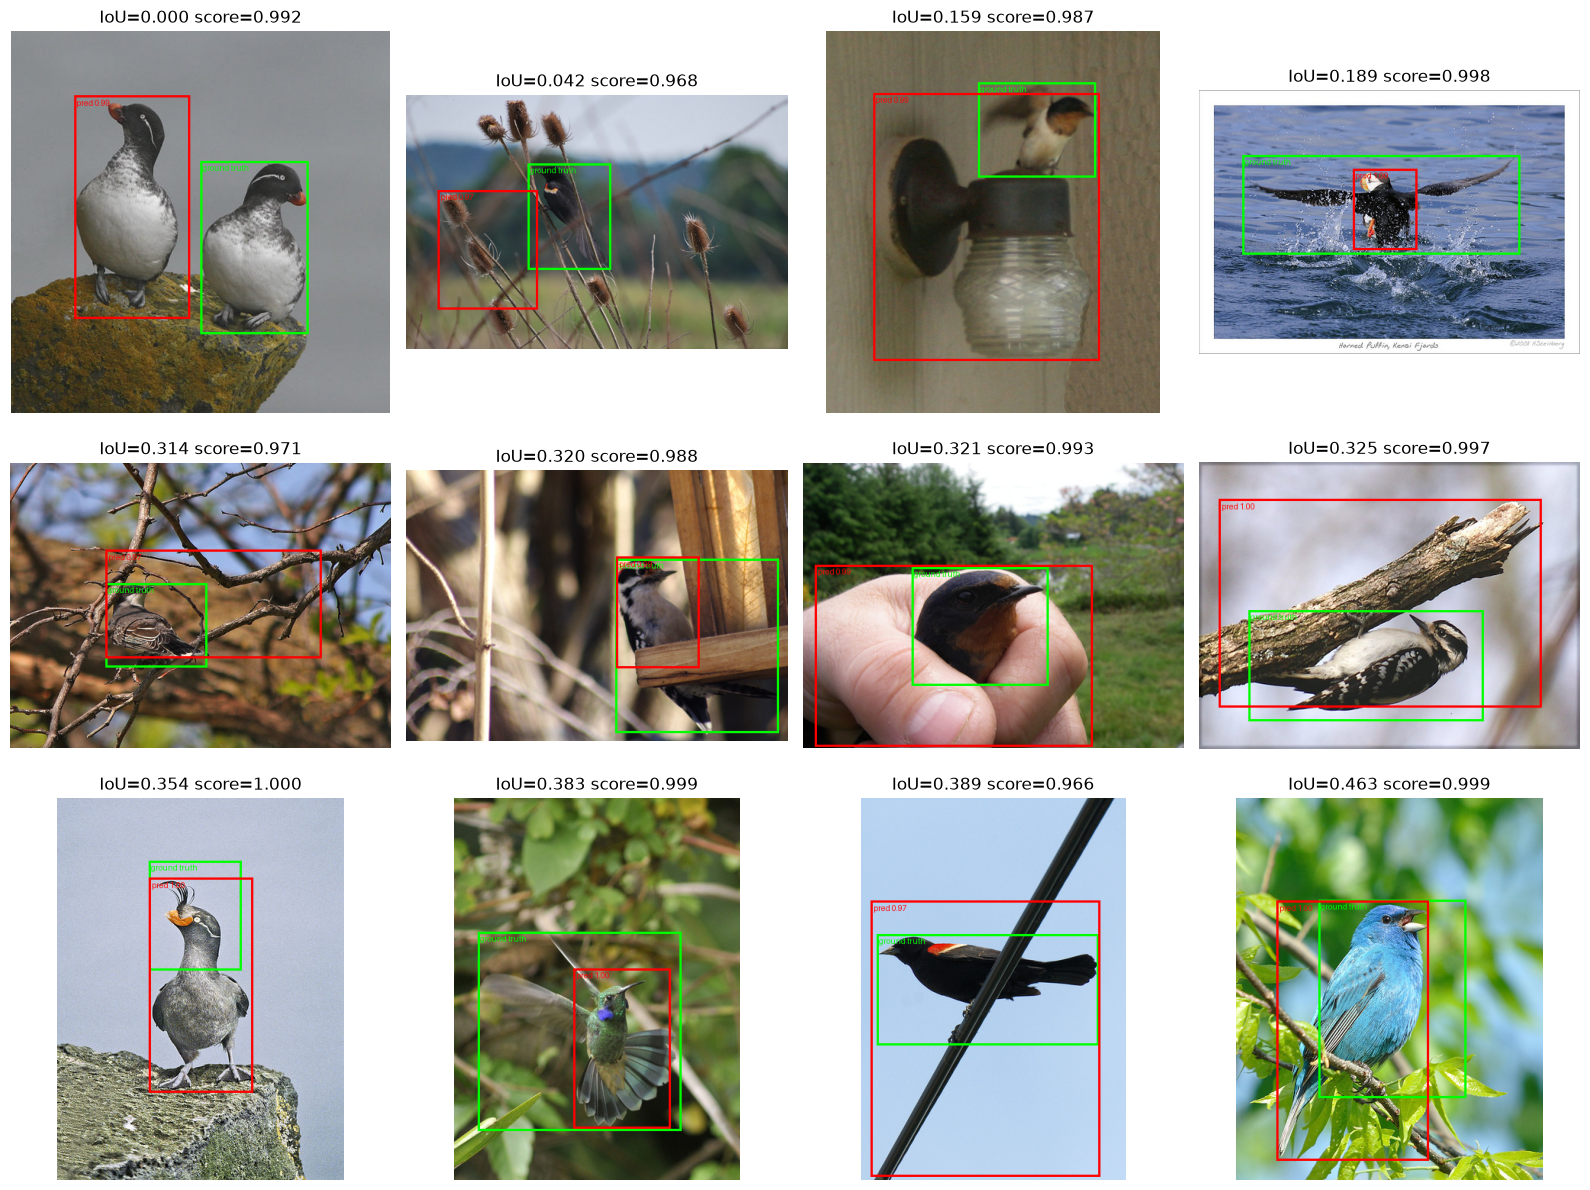

In [11]:
def draw_box(
    draw: ImageDraw.ImageDraw,
    box: Sequence[float] | None,
    color: str,
    label: str,
    width: int = 3,
) -> None:
    if box is None:
        return
    coordinates = tuple(float(value) for value in box)
    draw.rectangle(coordinates, outline=color, width=width)
    draw.text((coordinates[0] + 3, coordinates[1] + 3), label, fill=color)


def show_cub_predictions(
    predictions: pd.DataFrame,
    count: int = 12,
    sort_by: str | None = None,
) -> None:
    shown = predictions.copy()
    if sort_by is not None:
        shown = shown.sort_values(sort_by)
    shown = shown.head(min(count, len(shown)))
    columns = 4
    rows = math.ceil(len(shown) / columns)
    fig, axes = plt.subplots(rows, columns, figsize=(16, 4 * rows), squeeze=False)
    for ax, (_, row) in zip(axes.ravel(), shown.iterrows()):
        with Image.open(row["path"]) as opened:
            image = opened.convert("RGB")
        draw = ImageDraw.Draw(image)
        draw_box(draw, row["ground_truth_box"], "lime", "ground truth")
        if pd.notna(row["score"]) and float(row["score"]) >= selected_threshold:
            draw_box(draw, row["predicted_box"], "red", f"pred {row['score']:.2f}")
        ax.imshow(image)
        ax.set_title(f"IoU={row['iou_if_detected']:.3f} score={row['score']:.3f}")
        ax.axis("off")
    for ax in axes.ravel()[len(shown):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()


print("Lowest-IoU accepted CUB test predictions (green=ground truth, red=prediction)")
accepted_test = test_predictions.loc[
    test_predictions["score"].fillna(-1).ge(selected_threshold)
]
show_cub_predictions(accepted_test, count=12, sort_by="iou_if_detected")


## 7. Resumable iNaturalist inference

The progress filename includes a run signature derived from the source manifest,
checkpoint, threshold, and row limit. Each completed image is flushed as one JSON
record. Corrupt or unreadable images become `image_error` rows instead of
terminating the full run.

Changing the checkpoint or threshold automatically creates a different progress
file. Delete that specific progress file only when intentionally restarting the
same run from zero.


In [12]:
checkpoint_sha256 = sha256_file(checkpoint_to_load)
inat_manifest_sha256 = sha256_file(INAT_MANIFEST)
run_signature_payload = {
    "model": MODEL_NAME,
    "checkpoint_sha256": checkpoint_sha256,
    "inaturalist_manifest_sha256": inat_manifest_sha256,
    "threshold": selected_threshold,
    "limit": INATURALIST_LIMIT,
}
run_signature = hashlib.sha256(
    json.dumps(run_signature_payload, sort_keys=True).encode("utf-8")
).hexdigest()[:16]
PROGRESS_JSONL = BBOX_OUTPUT_DIR / f"inaturalist_bbox_progress_{run_signature}.jsonl"

inat_to_process = inat if INATURALIST_LIMIT is None else inat.head(INATURALIST_LIMIT).copy()


def read_progress(path: Path) -> dict[int, dict[str, Any]]:
    records: dict[int, dict[str, Any]] = {}
    if not path.is_file():
        return records
    with path.open("r", encoding="utf-8") as handle:
        for line_number, line in enumerate(handle, start=1):
            if not line.strip():
                continue
            try:
                record = json.loads(line)
                records[int(record["row_index"])] = record
            except (json.JSONDecodeError, KeyError, TypeError, ValueError) as exc:
                # A final partial line can result from an abrupt process termination.
                print(f"Ignoring invalid progress line {line_number}: {exc}")
    return records


def load_image_for_inference(path: str) -> tuple[torch.Tensor, int, int]:
    with Image.open(path) as opened:
        image = opened.convert("RGB")
    width, height = image.size
    return pil_to_tensor(image).float() / 255.0, width, height


def prediction_record(
    row: pd.Series,
    prediction: dict[str, Any] | None,
    width: int | None,
    height: int | None,
    error: str | None = None,
) -> dict[str, Any]:
    base = {
        "row_index": int(row["_row_index"]),
        "source_image_id": str(row["_source_image_id"]),
        "bbox_image_width_px": width,
        "bbox_image_height_px": height,
        "bbox_x": None,
        "bbox_y": None,
        "bbox_width": None,
        "bbox_height": None,
        "bbox_right": None,
        "bbox_bottom": None,
        "bbox_area_fraction": None,
        "bbox_within_image": None,
        "bbox_confidence": None,
        "bird_detection_count": 0,
        "bbox_detection_status": "image_error" if error else "no_bird_detection",
        "bbox_error": error,
    }
    if error or prediction is None:
        return base

    base["bird_detection_count"] = int(prediction["bird_detection_count"])
    score, box = prediction["score"], prediction["box"]
    if score is None or box is None:
        return base
    base["bbox_confidence"] = float(score)
    if score < selected_threshold:
        base["bbox_detection_status"] = "below_threshold"
        return base

    assert width is not None and height is not None
    x1 = min(max(float(box[0]), 0.0), float(width))
    y1 = min(max(float(box[1]), 0.0), float(height))
    x2 = min(max(float(box[2]), 0.0), float(width))
    y2 = min(max(float(box[3]), 0.0), float(height))
    if x2 <= x1 or y2 <= y1:
        base["bbox_detection_status"] = "invalid_box"
        return base

    box_width, box_height = x2 - x1, y2 - y1
    base.update(
        {
            "bbox_x": x1,
            "bbox_y": y1,
            "bbox_width": box_width,
            "bbox_height": box_height,
            "bbox_right": x2,
            "bbox_bottom": y2,
            "bbox_area_fraction": (box_width * box_height) / (width * height),
            "bbox_within_image": True,
            "bbox_detection_status": "detected",
        }
    )
    return base


if not RESUME_INFERENCE and PROGRESS_JSONL.exists():
    PROGRESS_JSONL.unlink()
completed = read_progress(PROGRESS_JSONL) if RESUME_INFERENCE else {}
pending = inat_to_process.loc[~inat_to_process["_row_index"].isin(completed)].copy()
print(f"Run signature: {run_signature}")
print(f"Already completed: {len(completed):,}")
print(f"Pending:           {len(pending):,}")
print(f"Progress file:     {PROGRESS_JSONL}")


Run signature: d259a16046822f0f
Already completed: 0
Pending:           74,300
Progress file:     /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Notebooks/Outputs/iNaturalist Outputs/Bounding Box Outputs/inaturalist_bbox_progress_d259a16046822f0f.jsonl


In [13]:
def append_progress(handle: Any, records: Iterable[dict[str, Any]]) -> None:
    for record in records:
        handle.write(json.dumps(json_safe(record), ensure_ascii=False) + "\n")
    handle.flush()


if RUN_INATURALIST_INFERENCE and len(pending):
    model.eval()
    started = time.perf_counter()
    processed_this_run = 0
    pending_rows = [row for _, row in pending.iterrows()]

    # Ensure an interrupted partial final line cannot consume the first resumed record.
    if PROGRESS_JSONL.is_file() and PROGRESS_JSONL.stat().st_size:
        with PROGRESS_JSONL.open("rb") as existing_handle:
            existing_handle.seek(-1, os.SEEK_END)
            ends_with_newline = existing_handle.read(1) == b"\n"
        if not ends_with_newline:
            with PROGRESS_JSONL.open("ab") as repair_handle:
                repair_handle.write(b"\n")

    # Append mode is deliberate: existing records belong to this exact run signature.
    with PROGRESS_JSONL.open("a", encoding="utf-8", buffering=1) as progress_handle:
        for batch_start in range(0, len(pending_rows), INFERENCE_BATCH_SIZE):
            batch_rows = pending_rows[batch_start : batch_start + INFERENCE_BATCH_SIZE]
            valid_rows: list[pd.Series] = []
            images: list[torch.Tensor] = []
            dimensions: list[tuple[int, int]] = []

            for row in batch_rows:
                try:
                    image, width, height = load_image_for_inference(row["_path"])
                    images.append(image)
                    dimensions.append((width, height))
                    valid_rows.append(row)
                except Exception as exc:
                    record = prediction_record(
                        row, None, None, None,
                        error=f"{type(exc).__name__}: {exc}",
                    )
                    append_progress(progress_handle, [record])
                    completed[int(row["_row_index"])] = record
                    processed_this_run += 1

            if images:
                try:
                    with torch.inference_mode():
                        outputs = model(
                            [image.to(DEVICE, non_blocking=True) for image in images]
                        )
                    batch_records = []
                    for row, (width, height), output in zip(valid_rows, dimensions, outputs):
                        prediction = highest_bird_prediction(output)
                        record = prediction_record(row, prediction, width, height)
                        batch_records.append(record)
                        completed[int(row["_row_index"])] = record
                    append_progress(progress_handle, batch_records)
                    processed_this_run += len(batch_records)
                except RuntimeError as exc:
                    # A batch-level CUDA error should not mislabel all images as corrupt.
                    # Stop with flushed progress so batch size/settings can be adjusted safely.
                    if DEVICE.type == "cuda":
                        torch.cuda.empty_cache()
                    raise RuntimeError(
                        f"Detector failed at pending batch offset {batch_start}. "
                        "Progress through the previous batch is saved. Reduce "
                        "INFERENCE_BATCH_SIZE if this was an out-of-memory error."
                    ) from exc

            if processed_this_run % 500 < len(batch_rows) or processed_this_run == len(pending_rows):
                elapsed = time.perf_counter() - started
                rate = processed_this_run / elapsed if elapsed else 0.0
                remaining = len(pending_rows) - processed_this_run
                eta_minutes = remaining / rate / 60 if rate else math.inf
                print(
                    f"Processed {processed_this_run:,}/{len(pending_rows):,} this run | "
                    f"{rate:.2f} images/s | ETA {eta_minutes:.1f} min",
                    flush=True,
                )
elif not RUN_INATURALIST_INFERENCE:
    print("RUN_INATURALIST_INFERENCE=False; no new images processed")
else:
    print("Inference is already complete for this run signature")

completed = read_progress(PROGRESS_JSONL)
expected_indices = set(inat_to_process["_row_index"].astype(int))
missing_indices = expected_indices - set(completed)
if RUN_INATURALIST_INFERENCE and missing_indices:
    raise AssertionError(f"Inference ended with {len(missing_indices):,} unprocessed rows")
print(f"Progress records available: {len(completed):,}")


Processed 500/74,300 this run | 14.58 images/s | ETA 84.3 min
Processed 1,000/74,300 this run | 13.78 images/s | ETA 88.7 min
Processed 1,500/74,300 this run | 13.46 images/s | ETA 90.1 min
Processed 2,000/74,300 this run | 13.52 images/s | ETA 89.1 min
Processed 2,500/74,300 this run | 13.67 images/s | ETA 87.6 min
Processed 3,000/74,300 this run | 14.47 images/s | ETA 82.1 min
Processed 3,500/74,300 this run | 14.43 images/s | ETA 81.8 min
Processed 4,000/74,300 this run | 14.56 images/s | ETA 80.5 min
Processed 4,500/74,300 this run | 14.71 images/s | ETA 79.1 min
Processed 5,000/74,300 this run | 15.02 images/s | ETA 76.9 min
Processed 5,500/74,300 this run | 15.08 images/s | ETA 76.0 min
Processed 6,000/74,300 this run | 15.38 images/s | ETA 74.0 min
Processed 6,500/74,300 this run | 15.57 images/s | ETA 72.6 min
Processed 7,000/74,300 this run | 15.83 images/s | ETA 70.8 min
Processed 7,500/74,300 this run | 16.01 images/s | ETA 69.5 min
Processed 8,000/74,300 this run | 16.10 im

## 8. Export CUB-style manifest and audit artifacts

The output retains all original input columns. Existing bounding-box columns are
replaced for the selected iNaturalist rows, and provenance fields make it clear
that the values are detector-generated. CSV files use UTF-8 with a BOM for
spreadsheet compatibility.


In [14]:
if not completed:
    raise RuntimeError(
        "No inference records are available. Enable inference or provide a completed "
        "progress file for the current run signature."
    )

prediction_frame = pd.DataFrame(completed.values()).sort_values("row_index")
prediction_frame = prediction_frame.loc[
    prediction_frame["row_index"].isin(expected_indices)
].copy()
if len(prediction_frame) != len(inat_to_process):
    raise AssertionError(
        f"Expected {len(inat_to_process):,} predictions, found {len(prediction_frame):,}"
    )
if prediction_frame["row_index"].duplicated().any():
    raise AssertionError("Prediction row indices are not unique")

export = inat_to_process.copy()
internal_columns = [column for column in export if column.startswith("_")]
export = export.drop(columns=internal_columns)

bbox_columns = [
    "bbox_x", "bbox_y", "bbox_width", "bbox_height", "bbox_right", "bbox_bottom",
    "bbox_area_fraction", "bbox_within_image", "bbox_confidence",
    "bird_detection_count", "bbox_detection_status", "bbox_error",
    "bbox_image_width_px", "bbox_image_height_px",
]
export = export.drop(columns=[column for column in bbox_columns if column in export], errors="ignore")
prediction_export = prediction_frame.set_index("row_index")[bbox_columns]
prediction_export = prediction_export.reindex(inat_to_process["_row_index"].astype(int))
prediction_export.index = export.index
export = pd.concat([export, prediction_export], axis=1)

export["bbox_source"] = "pseudo_label"
export["bbox_model"] = MODEL_NAME
export["bbox_bird_class_id"] = BIRD_CLASS_ID
export["bbox_confidence_threshold"] = selected_threshold
export["bbox_checkpoint_sha256"] = checkpoint_sha256
export["bbox_generated_utc"] = utc_now()

MAIN_OUTPUT_CSV = BBOX_OUTPUT_DIR / "inaturalist_bird_bbox_manifest.csv"
FAILURES_OUTPUT_CSV = BBOX_OUTPUT_DIR / "inaturalist_bird_bbox_failures.csv"
SUMMARY_OUTPUT_JSON = BBOX_OUTPUT_DIR / "inaturalist_bird_bbox_summary.json"

export.to_csv(MAIN_OUTPUT_CSV, index=False, encoding="utf-8-sig")
failures = export.loc[~export["bbox_detection_status"].eq("detected")].copy()
failures.to_csv(FAILURES_OUTPUT_CSV, index=False, encoding="utf-8-sig")

detected = export.loc[export["bbox_detection_status"].eq("detected")].copy()
status_counts = export["bbox_detection_status"].value_counts(dropna=False).to_dict()
summary = {
    "generated_utc": utc_now(),
    "run_signature": run_signature,
    "source_manifest": str(INAT_MANIFEST),
    "source_manifest_kind": INAT_MANIFEST_KIND,
    "source_manifest_sha256": inat_manifest_sha256,
    "cub_manifest": str(CUB_MANIFEST),
    "cub_manifest_sha256": sha256_file(CUB_MANIFEST),
    "checkpoint": str(checkpoint_to_load),
    "checkpoint_sha256": checkpoint_sha256,
    "model": MODEL_NAME,
    "bird_class_id": BIRD_CLASS_ID,
    "confidence_threshold": selected_threshold,
    "threshold_selection": (
        "manual" if MANUAL_CONFIDENCE_THRESHOLD is not None
        else "highest threshold within 0.01 of best CUB validation Recall@IoU0.50"
    ),
    "input_rows": int(len(inat_to_process)),
    "status_counts": {str(key): int(value) for key, value in status_counts.items()},
    "detected_fraction": float(len(detected) / len(export)) if len(export) else 0.0,
    "bbox_area_fraction": {
        "minimum": safe_float(detected["bbox_area_fraction"].min()),
        "median": safe_float(detected["bbox_area_fraction"].median()),
        "maximum": safe_float(detected["bbox_area_fraction"].max()),
    },
    "bbox_confidence": {
        "minimum_detected": safe_float(detected["bbox_confidence"].min()),
        "median_detected": safe_float(detected["bbox_confidence"].median()),
        "maximum_detected": safe_float(detected["bbox_confidence"].max()),
    },
    "cub_metrics": {
        row["split"]: {
            key: json_safe(value) for key, value in row.items() if key != "split"
        }
        for row in cub_metrics.to_dict(orient="records")
    },
    "outputs": {
        "manifest": str(MAIN_OUTPUT_CSV),
        "manifest_sha256": sha256_file(MAIN_OUTPUT_CSV),
        "failures": str(FAILURES_OUTPUT_CSV),
        "failures_sha256": sha256_file(FAILURES_OUTPUT_CSV),
        "cub_metrics": str(BBOX_OUTPUT_DIR / "cub_bird_detector_metrics.csv"),
        "progress": str(PROGRESS_JSONL),
    },
    "limitations": [
        "Bounding boxes are model-generated pseudo-labels, not human annotations.",
        "Only the highest-confidence bird is retained, matching CUB's one-box-per-image convention.",
        "Threshold validation uses positive bird images and does not estimate non-bird false-positive rate.",
        "Review low-confidence, extreme-area, multiple-detection, and missing-detection samples before training.",
    ],
}
SUMMARY_OUTPUT_JSON.write_text(
    json.dumps(json_safe(summary), ensure_ascii=False, indent=2), encoding="utf-8"
)

print(f"Manifest: {MAIN_OUTPUT_CSV} ({len(export):,} rows)")
print(f"Failures: {FAILURES_OUTPUT_CSV} ({len(failures):,} rows)")
print(f"Summary:  {SUMMARY_OUTPUT_JSON}")
display(pd.Series(status_counts, name="images").to_frame())


Manifest: /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Notebooks/Outputs/iNaturalist Outputs/Bounding Box Outputs/inaturalist_bird_bbox_manifest.csv (74,300 rows)
Failures: /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Notebooks/Outputs/iNaturalist Outputs/Bounding Box Outputs/inaturalist_bird_bbox_failures.csv (21,193 rows)
Summary:  /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Notebooks/Outputs/iNaturalist Outputs/Bounding Box Outputs/inaturalist_bird_bbox_summary.json


,images
detected,53107
below_threshold,18973
no_bird_detection,2220


## 9. Output validation and QA

These checks verify coordinate bounds, row identity/order, source-image
dimensions, output hashes, and status/box consistency. They do not establish
semantic correctness, so the visual review that follows remains required.


In [ ]:
source_ids = inat_to_process["_source_image_id"].astype(str).tolist()
if "source_image_id" in export:
    exported_ids = export["source_image_id"].astype(str).tolist()
else:
    exported_ids = export["image_id"].astype(str).tolist()

coordinate_checks = {
    "output_row_count_matches_input": len(export) == len(inat_to_process),
    "source_image_identity_and_order_preserved": source_ids == exported_ids,
    "source_image_ids_are_unique": len(source_ids) == len(set(source_ids)),
    "all_statuses_are_known": export["bbox_detection_status"].isin(
        ["detected", "below_threshold", "no_bird_detection", "invalid_box", "image_error"]
    ).all(),
    "detected_rows_have_all_box_fields": detected[
        ["bbox_x", "bbox_y", "bbox_width", "bbox_height", "bbox_right", "bbox_bottom"]
    ].notna().all().all(),
    "non_detected_rows_have_no_box": failures[
        ["bbox_x", "bbox_y", "bbox_width", "bbox_height"]
    ].isna().all().all(),
    "box_origins_are_non_negative": detected["bbox_x"].ge(0).all() and detected["bbox_y"].ge(0).all(),
    "box_dimensions_are_positive": detected["bbox_width"].gt(0).all() and detected["bbox_height"].gt(0).all(),
    "box_right_within_actual_width": (
        detected["bbox_right"] <= prediction_frame.set_index("row_index")
        .reindex(inat_to_process["_row_index"].astype(int))["bbox_image_width_px"].set_axis(export.index)
        .loc[detected.index] + 1e-6
    ).all(),
    "box_bottom_within_actual_height": (
        detected["bbox_bottom"] <= prediction_frame.set_index("row_index")
        .reindex(inat_to_process["_row_index"].astype(int))["bbox_image_height_px"].set_axis(export.index)
        .loc[detected.index] + 1e-6
    ).all(),
    "area_fraction_is_valid": detected["bbox_area_fraction"].between(0, 1, inclusive="both").all(),
    "confidence_is_valid": export["bbox_confidence"].dropna().between(0, 1, inclusive="both").all(),
    "all_detected_confidences_meet_threshold": detected["bbox_confidence"].ge(selected_threshold).all(),
    "manifest_was_written": MAIN_OUTPUT_CSV.is_file() and MAIN_OUTPUT_CSV.stat().st_size > 0,
    "summary_was_written": SUMMARY_OUTPUT_JSON.is_file() and SUMMARY_OUTPUT_JSON.stat().st_size > 0,
}
validation_table = pd.Series(coordinate_checks, name="passed").to_frame()
display(validation_table)
if not all(coordinate_checks.values()):
    failed = [name for name, passed in coordinate_checks.items() if not passed]
    raise AssertionError(f"Output validation failed: {failed}")

# Re-read key fields to catch serialization or row-count mistakes.
round_trip = pd.read_csv(
    MAIN_OUTPUT_CSV,
    encoding="utf-8-sig",
    usecols=[
        "bbox_x", "bbox_y", "bbox_width", "bbox_height",
        "bbox_detection_status", "bbox_checkpoint_sha256",
    ],
    low_memory=False,
)
assert len(round_trip) == len(export)
assert round_trip["bbox_checkpoint_sha256"].eq(checkpoint_sha256).all()
assert round_trip.loc[
    round_trip["bbox_detection_status"].eq("detected"),
    ["bbox_x", "bbox_y", "bbox_width", "bbox_height"],
].notna().all().all()
print("CSV round-trip validation passed")


In [ ]:
if len(detected):
    cub_area = (
        (cub["_x2"] - cub["_x1"]) * (cub["_y2"] - cub["_y1"])
        / (cub["width_px"] * cub["height_px"])
    )
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    axes[0].hist(cub_area, bins=40, alpha=0.65, density=True, label="CUB ground truth")
    axes[0].hist(detected["bbox_area_fraction"], bins=40, alpha=0.65, density=True, label="iNaturalist pseudo-label")
    axes[0].set(title="Bounding-box area distributions", xlabel="box area / image area", ylabel="density")
    axes[0].legend()
    axes[1].hist(detected["bbox_confidence"], bins=40, color="#4c72b0")
    axes[1].axvline(selected_threshold, color="black", linestyle="--")
    axes[1].set(title="Accepted iNaturalist confidence", xlabel="confidence", ylabel="images")
    plt.tight_layout()
    plt.show()


In [ ]:
def qa_selection(frame: pd.DataFrame, count: int) -> pd.DataFrame:
    if frame.empty:
        return frame
    per_group = max(1, count // 4)
    random_sample = frame.sample(min(per_group, len(frame)), random_state=SEED)
    selections = [
        frame.nsmallest(per_group, "bbox_confidence"),
        frame.nsmallest(per_group, "bbox_area_fraction"),
        frame.nlargest(per_group, "bbox_area_fraction"),
        random_sample,
    ]
    return pd.concat(selections).loc[lambda value: ~value.index.duplicated()].head(count)


def render_inaturalist_qa(rows: pd.DataFrame, destination: Path | None = None) -> None:
    if rows.empty:
        print("No accepted detections are available for QA")
        return
    columns = 4
    grid_rows = math.ceil(len(rows) / columns)
    fig, axes = plt.subplots(grid_rows, columns, figsize=(16, 4 * grid_rows), squeeze=False)
    for ax, (index, row) in zip(axes.ravel(), rows.iterrows()):
        source_row = inat_to_process.loc[index]
        with Image.open(source_row["_path"]) as opened:
            image = opened.convert("RGB")
        draw = ImageDraw.Draw(image)
        box = [row["bbox_x"], row["bbox_y"], row["bbox_right"], row["bbox_bottom"]]
        draw_box(draw, box, "red", f"bird {row['bbox_confidence']:.2f}", width=max(2, round(min(image.size) / 150)))
        ax.imshow(image)
        ax.set_title(
            f"id={source_row['_source_image_id']} score={row['bbox_confidence']:.3f}\n"
            f"area={row['bbox_area_fraction']:.3f} detections={int(row['bird_detection_count'])}",
            fontsize=8,
        )
        ax.axis("off")
    for ax in axes.ravel()[len(rows):]:
        ax.axis("off")
    plt.tight_layout()
    if destination is not None:
        fig.savefig(destination, dpi=140, bbox_inches="tight")
        print(f"Saved QA preview: {destination}")
    plt.show()


if SAVE_QA_PREVIEWS:
    qa_rows = qa_selection(detected, QA_PREVIEW_COUNT)
    render_inaturalist_qa(qa_rows, PREVIEW_DIR / f"inaturalist_bbox_qa_{run_signature}.jpg")

review_table = pd.concat(
    {
        "lowest_confidence": detected.nsmallest(10, "bbox_confidence"),
        "smallest_area": detected.nsmallest(10, "bbox_area_fraction"),
        "largest_area": detected.nlargest(10, "bbox_area_fraction"),
        "most_detections": detected.nlargest(10, "bird_detection_count"),
    },
    names=["review_reason", "source_row"],
).reset_index(level=0)
display(
    review_table[
        ["review_reason", "bbox_confidence", "bbox_area_fraction", "bird_detection_count"]
    ]
)


## 10. Interpretation and downstream use

* Treat `bbox_source == "pseudo_label"` differently from human CUB annotations.
* Review `inaturalist_bird_bbox_failures.csv`; do not replace missing detections
  with a full-frame box without explicitly deciding that policy downstream.
* Images with `bird_detection_count > 1`, extreme `bbox_area_fraction`, or scores
  near the threshold are the highest-priority candidates for manual review.
* The highest-confidence box convention intentionally drops secondary birds so
  output remains compatible with CUB's single-box-per-image schema.
* Keep the checkpoint hash and summary with any derived training manifest so the
  pseudo-labeling run remains reproducible.
